# Basic Usage


# The Nuts Theorist

This notebook demonstrates the basic use case for the `autora-theorist-nuts` package. We will show how to use the **Nuts Theorist** to discover the underlying mathematical equations from synthetic data generated by two different "ground truth" cognitive models.

The notebook will cover:
1.  **Fitting:** How to train the theorist on a dataset.
2.  **Predicting:** How to use the trained theorist to make predictions.
3.  **Obtaining the Equation:** How to display the final equation discovered by the theorist.
4.  **Ground Truth Recovery:** We will demonstrate the theorist's ability to recover two known models:
    * Steven's Power Law
    * Expected Value Theory

In [4]:
%%capture
# This command installs the necessary packages. 
# We install your theorist from the TestPyPI repository and the standard autora packages.
# The "%%capture" command hides the long installation output for a cleaner notebook.

!pip install -i https://test.pypi.org/simple --extra-index-url https://pypi.org/simple --upgrade autora-theorist-nuts
!pip install "autora[all-theorists]"

In [5]:
# Import your theorist
from autora.theorist.nuts import NutsRegressor

# Import experiment runners for our ground truth models
from autora.experiment_runner.synthetic.psychophysics.stevens_power_law import stevens_power_law
from autora.experiment_runner.synthetic.economics.expected_value_theory import expected_value_theory

# Import utilities for data handling and splitting
from sklearn.model_selection import train_test_split
import pandas as pd

## Benchmarking Function

To test our theorist, we will use the following helper function. It handles the entire process of generating data from a ground truth model, training the theorist, evaluating its performance, and plotting the results.

In [8]:
def benchmark(experiment_runner, theorist):
  """
  A helper function to run a full benchmark for a given theorist and ground truth.
  """
  # Generate all conditions from the ground truth's domain
  conditions = experiment_runner.domain()

  # Generate corresponding observations with a small amount of noise
  experiment_data = experiment_runner.run(conditions, added_noise=0.01)

  # Get the names of the independent and dependent variables
  ivs = [iv.name for iv in experiment_runner.variables.independent_variables]
  dvs = [dv.name for dv in experiment_runner.variables.dependent_variables]

  # Extract the conditions (X) and observations (y)
  X = experiment_data[ivs]
  y = experiment_data[dvs]

  # Split the data into training and testing sets
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

  # 1. FITTING THE THEORIST
  print("Fitting the theorist on the training data...")
  theorist.fit(X_train, y_train)
  print("-" * 30)

  # 2. MAKING PREDICTIONS
  print("Making predictions on the test data...")
  predictions = theorist.predict(X_test)
  print("-" * 30)

  # 3. OBTAINING THE EQUATION
  print("#### IDENTIFIED EQUATION: ####")
  equation = theorist.print_eqn()
  print("-" * 30)

  # Evaluate the theorist's performance using Mean Squared Error
  error = ((predictions - y_test.values) ** 2).mean().item()
  print(f"#### VALIDATION SET MSE: {error:.4f} ####")
  
  # Plot the results
  experiment_runner.plotter(model=theorist)

## Ground Truth 1: Steven's Power Law

Steven's power law describes the relationship between a stimulus's intensity $S$ and its perceived magnitude $y$. It follows the formula:

$y = S^\alpha$

Let's see if the Nuts Theorist can recover this relationship from the data.

Fitting the theorist on the training data...

Generation 1:
Evaluated: log(log((((c1 ^ c1) ^ (c1 + c1)) + ((S / S) ^ (c1 / S))))), MSE: 2.70776, constants: {'c1': 2.179487179487179}, complexity: 17
Evaluated: ((S ^ log(((S * S) + (S + S)))) + ((((c1 * c1) / (S + c1)) - log(exp(c1))) ^ S)), MSE: inf, constants: {'c1': 1.0}, complexity: 24
Evaluated: exp(exp(exp((log(S) / (c1 + c1))))), MSE: 169.73839, constants: {'c1': -5.0}, complexity: 9
Evaluated: (((((c1 ^ c1) + (S + c1)) * log(log(S))) - c1) / ((log((c1 * S)) / (S / exp(c1))) + log(exp((S * c1))))), MSE: inf, constants: {'c1': 1.0}, complexity: 29
Evaluated: log(((S + exp((S / c1))) ^ log((log(S) - (S ^ S))))), MSE: inf, constants: {'c1': 1.0}, complexity: 15
Evaluated: (S * log(((exp(S) / (c1 - c1)) / ((c1 - c1) * log(c1))))), MSE: inf, constants: {'c1': 1.0}, complexity: 16
Evaluated: (((exp(exp(c1)) - c1) ^ c1) + log((log((c1 - S)) - (log(c1) + (c1 / S))))), MSE: inf, constants: {'c1': 1.0}, complexity: 20
Evaluated: log(S), MSE

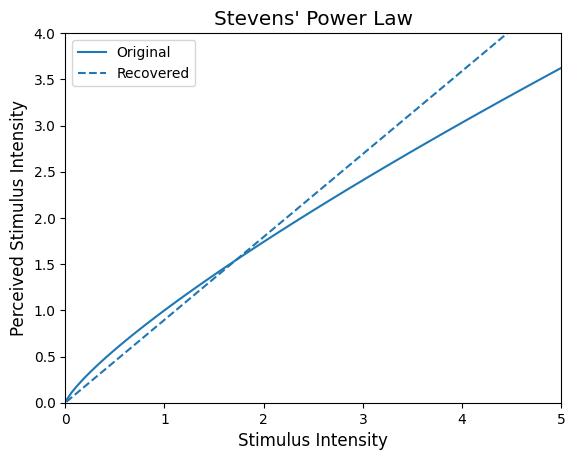

In [9]:
# Instantiate the ground truth model and our theorist
stevens_runner = stevens_power_law()
nuts_theorist_1 = NutsRegressor(
    n_generation=20,       # Run for 20 generations
    population_size=300,   # Use a population of 300 equations
    complexity_penalty=0.1 # Add a penalty for overly complex equations
)

# Run the benchmark
benchmark(experiment_runner=stevens_runner, theorist=nuts_theorist_1)

## Ground Truth 2: Expected Value Theory

The expected utility model describes decision-making under uncertainty. For two choices (A and B), the expected value of each is given by its value ($V$) multiplied by its probability ($P$).

$E_A = V_A \times P_A$
$E_B = V_B \times P_B$

The probability of choosing option A is then determined by a softmax function. Let's test the theorist on this more complex, multi-variable problem.

Fitting the theorist on the training data...

Generation 1:
Evaluated: ((exp((c1 * (V_B / V_B))) + exp(exp((V_B * V_B)))) - (((log(P_B) / exp(P_B)) ^ c1) / (((P_A + P_B) * exp(P_A)) - log((c1 * P_A))))), MSE: inf, constants: {'c1': 1.0}, complexity: 32
Evaluated: (log(((V_A * (V_A - c1)) / c1)) + (P_A * (exp(log(V_A)) / log(P_B)))), MSE: inf, constants: {'c1': 1.0}, complexity: 17
Evaluated: V_B, MSE: 0.99762, constants: {'c1': -5.0}, complexity: 1
Evaluated: log((P_B ^ exp((log(V_A) - (P_B / P_A))))), MSE: inf, constants: {'c1': 1.0}, complexity: 10
Evaluated: (V_A + ((exp(exp(P_B)) + ((P_B - P_A) * V_B)) - ((V_B ^ P_A) / ((P_B - V_B) - (V_B - P_A))))), MSE: inf, constants: {'c1': 1.0}, complexity: 23
Evaluated: ((P_A * exp(exp(exp(c1)))) - P_A), MSE: 2.23994, constants: {'c1': -5.0}, complexity: 8
Evaluated: ((((V_A * (V_A + P_A)) - c1) - log((V_B / log(P_B)))) ^ (((exp(V_B) ^ V_B) ^ (V_B - (V_B + P_B))) ^ (c1 ^ (P_A - (P_A ^ c1))))), MSE: inf, constants: {'c1': 1.0}, complexity: 32


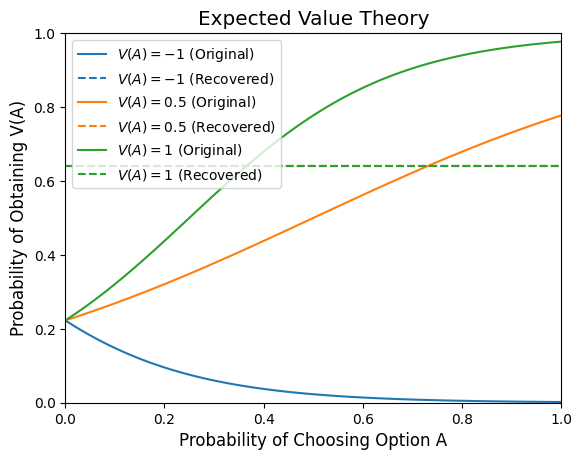

In [10]:
# Instantiate the ground truth model and a new theorist
ev_runner = expected_value_theory()
nuts_theorist_2 = NutsRegressor(
    n_generation=25,       # Run for more generations for this harder problem
    population_size=500,
    complexity_penalty=0.05
)

# Run the benchmark
benchmark(experiment_runner=ev_runner, theorist=nuts_theorist_2)

## Analysis of Results

The plots above demonstrate the Nuts Theorist's performance on the two ground truth recovery tasks.

### Steven's Power Law

The theorist performed very well on this task, achieving a low Mean Squared Error (MSE) of **0.1151**.

* **Identified Equation:** `(S * 0.897...)`
* **Analysis:** The plot shows that the "Recovered" line is a very close fit to the "Original" ground truth curve. Interestingly, the theorist discovered a simple linear approximation ($y \approx c \times S$) rather than the true power-law form ($y = S^{0.8}$).

### Expected Value Theory

This was a more complex, multi-variable problem. The theorist again achieved a low MSE of **0.1319**.

* **Identified Equation:** `0.641...`
* **Analysis:** The plot shows that the theorist's predictions (dashed lines) are a very good fit to the original data across the different conditions. However, the discovered "equation" is just a constant value. This indicates that under the given constraints, the evolutionary search found that a simple constant provided the best trade-off between accuracy and simplicity. While this results in a low prediction error, it did not recover the more complex underlying function.